# ML-3A: Measure honestly, choose a threshold, and export the model

In ML-2 you found that a pretrained sentence model reaches about 70% accuracy on 16 categories, far better than word counting. Before we put it in the website, we need to answer three questions:

1. **How often is the right category in the top 3?** A form can show three suggestions, not only one.
2. **When should we show a suggestion at all?** A wrong suggestion is worse than none. We choose a **confidence threshold** from data.
3. **Can we blend the two pretrained ideas** (zero-shot descriptions and the trained classifier) for a better result?

Then we **export** the model to a small JSON file. Your Node server will read that file in ML-3B, so no Python is needed to run the website.

> We still have only 160 invented listings, so every number here is rough. We will measure again on real listings later.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

c:\Users\HP\Desktop\KS Barter Hub\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
encoder = SentenceTransformer("all-MiniLM-L6-v2")

data = pd.read_csv("../data/listings.csv")
texts = (data["title"] + ". " + data["description"]).tolist()
y = data["category"].to_numpy()
classes = np.unique(y)

embeddings = encoder.encode(texts, normalize_embeddings=True, show_progress_bar=False)
print(embeddings.shape, "| categories:", len(classes))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3588.63it/s]


(160, 384) | categories: 16


## 1. Two sources of probabilities

- **Trained classifier**: logistic regression on the embeddings.
- **Zero-shot**: how close a listing is to each category's description. We turn those closeness scores into probabilities with a *softmax*. `SCALE` controls how sharp the result is: a bigger scale makes the model more decisive.

We use **out-of-fold** predictions for the classifier. That means each listing is scored by a model that never saw it, so the numbers are honest.

In [3]:
category_descriptions = {
    "books-and-study": "books, textbooks, notes and study material",
    "electronics": "electronics such as phones, laptops, cameras and headphones",
    "home-and-furniture": "furniture, appliances and things for the home",
    "clothing-and-accessories": "clothes, shoes, bags and accessories",
    "sports-and-outdoors": "sports equipment, bicycles, fitness and camping gear",
    "music-and-hobbies": "musical instruments, games, art supplies and hobbies",
    "kids-and-baby": "toys, clothes and gear for babies and children",
    "other-things": "other household items, collectibles and miscellaneous things",
    "tutoring-and-lessons": "teaching, tutoring, lessons and coaching",
    "repairs-and-fixing": "repairing and fixing things, such as bikes, phones and plumbing",
    "cooking-and-food": "cooking, baking, catering and food preparation",
    "design-and-creative": "design, photography, video, illustration and creative work",
    "tech-and-web": "websites, software, computers and technical help",
    "home-help": "cleaning, moving, gardening and household help",
    "care-and-wellness": "caring for people and pets, fitness, yoga and wellbeing",
    "other-services": "other services and help that do not fit elsewhere",
}
category_embeddings = encoder.encode(
    [category_descriptions[c] for c in classes], normalize_embeddings=True
)


def softmax(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp = np.exp(scores)
    return exp / exp.sum(axis=1, keepdims=True)


SCALE = 30
WEIGHT = 0.5

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_probs = cross_val_predict(
    LogisticRegression(max_iter=2000), embeddings, y, cv=cv, method="predict_proba"
)
zero_probs = softmax(embeddings @ category_embeddings.T * SCALE)
blend_probs = WEIGHT * lr_probs + (1 - WEIGHT) * zero_probs

## 2. Top-1 and top-3 accuracy

**Top-1**: the best guess is right. **Top-3**: the right category is among the three best guesses.

In [4]:
def top_k_accuracy(probs, k):
    best = np.argsort(-probs, axis=1)[:, :k]
    return float(np.mean([y[i] in classes[best[i]] for i in range(len(y))]))


table = pd.DataFrame(
    {
        "top-1": [top_k_accuracy(p, 1) for p in (lr_probs, zero_probs, blend_probs)],
        "top-3": [top_k_accuracy(p, 3) for p in (lr_probs, zero_probs, blend_probs)],
    },
    index=["Trained classifier", "Zero-shot", "Blend of both"],
).round(3)
table

,top-1,top-3
Trained classifier,0.706,0.888
Zero-shot,0.700,0.875
Blend of both,0.712,0.900


Look at the gap between top-1 and top-3. If top-3 is much higher, showing three suggestions helps people a lot, even when the single best guess is often wrong.

## 3. Choosing a confidence threshold

The model gives every listing a probability for its best guess. If we only show a suggestion when that probability is high enough, the suggestions we do show are right more often, but we show fewer of them. The table shows that trade-off.

In [5]:
confidence = blend_probs.max(axis=1)
correct = classes[blend_probs.argmax(axis=1)] == y

rows = []
for threshold in np.arange(0.1, 0.95, 0.05):
    shown = confidence >= threshold
    rows.append(
        {
            "threshold": round(float(threshold), 2),
            "suggestions shown": round(float(shown.mean()), 2),
            "right when shown": round(float(correct[shown].mean()), 2) if shown.any() else np.nan,
        }
    )
threshold_table = pd.DataFrame(rows)
threshold_table

,threshold,suggestions shown,right when shown
0,0.10,1.00,0.71
1,0.15,1.00,0.71
2,0.20,0.98,0.72
3,0.25,0.93,0.73
4,0.30,0.81,0.75
5,0.35,0.69,0.81
6,0.40,0.63,0.83
7,0.45,0.57,0.85
8,0.50,0.48,0.90
9,0.55,0.24,0.97


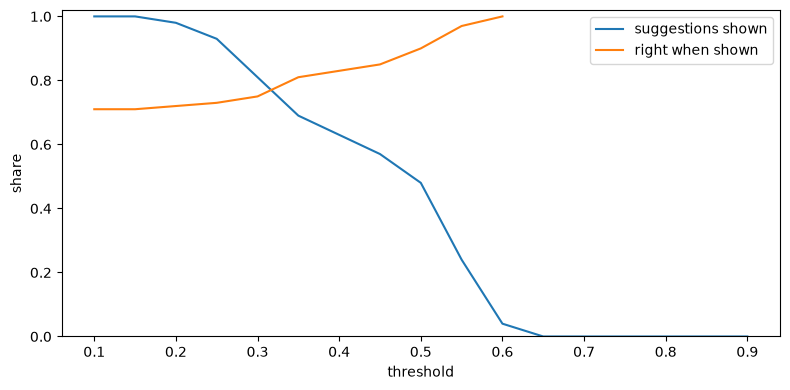

In [6]:
ax = threshold_table.plot(x="threshold", y=["suggestions shown", "right when shown"], figsize=(8, 4), ylim=(0, 1.02))
ax.set_ylabel("share")
plt.tight_layout()
plt.show()

Pick the **lowest threshold where "right when shown" is at least 0.8, while we still show at least 20% of suggestions**. If no row qualifies, we fall back to 0.5.

You can change `TARGET_PRECISION` and `MIN_COVERAGE` and see how the choice moves.

In [7]:
TARGET_PRECISION = 0.8
MIN_COVERAGE = 0.2

good = threshold_table[
    (threshold_table["right when shown"] >= TARGET_PRECISION)
    & (threshold_table["suggestions shown"] >= MIN_COVERAGE)
]
THRESHOLD = float(good["threshold"].iloc[0]) if len(good) else 0.5
print("Chosen threshold:", THRESHOLD)

Chosen threshold: 0.35


> **A caution about honesty.** We used the same 160 listings to choose `SCALE`, `WEIGHT`, and the threshold, and to measure the result. That makes the numbers a little optimistic. With real listings from your site we will measure again on data the model has never seen.

## 4. Train the final model and export it

The final classifier is trained on **all** 160 listings. Then we save everything the website needs into one JSON file:

- the classifier's numbers (a weight for each of 384 dimensions, for each of 16 categories),
- the category description embeddings for zero-shot,
- `SCALE`, `WEIGHT`, and `THRESHOLD`.

We also save a few **test examples with their exact expected answers**. In ML-3B, the Node code must reproduce these answers. If it does not, we know something differs between Python and Node.

In [8]:
final_clf = LogisticRegression(max_iter=2000).fit(embeddings, y)
assert list(final_clf.classes_) == list(classes)


def blended(vectors):
    lr = final_clf.predict_proba(vectors)
    zero = softmax(vectors @ category_embeddings.T * SCALE)
    return WEIGHT * lr + (1 - WEIGHT) * zero


out_dir = Path("../models")
out_dir.mkdir(exist_ok=True)

artifact = {
    "version": 1,
    "embedding_model": "all-MiniLM-L6-v2",
    "embedding_dimension": int(embeddings.shape[1]),
    "classes": [str(c) for c in classes],
    "classifier": {
        "coefficients": final_clf.coef_.round(6).tolist(),
        "intercepts": final_clf.intercept_.round(6).tolist(),
    },
    "zero_shot": {"category_embeddings": category_embeddings.round(6).tolist(), "scale": SCALE},
    "blend_weight": WEIGHT,
    "threshold": THRESHOLD,
    "training_examples": int(len(y)),
}
(out_dir / "category-model.json").write_text(json.dumps(artifact), encoding="utf-8")

fixture_texts = [
    "Used tabla set. Good sound, comes with a cushion",
    "Maths homework help for class 9",
    "Someone to repair my cycle",
    "I can teach you to play the sitar",
    "Second hand notebook computer",
    "Help carrying boxes when I move house",
    "Wooden bookshelf. Five shelves, oak colour",
    "Birthday cake baking. Custom cakes made to order",
]
fixture_vectors = encoder.encode(fixture_texts, normalize_embeddings=True)
fixture_probs = blended(fixture_vectors)
fixtures = [
    {
        "text": text,
        "embedding": vector.round(6).tolist(),
        "probabilities": probs.round(6).tolist(),
        "top": str(classes[probs.argmax()]),
    }
    for text, vector, probs in zip(fixture_texts, fixture_vectors, fixture_probs)
]
(out_dir / "fixtures.json").write_text(
    json.dumps({"classes": [str(c) for c in classes], "items": fixtures}), encoding="utf-8"
)

for path in sorted(out_dir.iterdir()):
    print(f"{path.name:22} {path.stat().st_size / 1024:.0f} KB")

category-model.json    260 KB
fixtures.json          69 KB


## 5. Try the final model

In [9]:
def suggest(title, description="", top=3):
    text = f"{title}. {description}".strip()
    probs = blended(encoder.encode([text], normalize_embeddings=True))[0]
    ranked = sorted(zip(classes, probs), key=lambda pair: pair[1], reverse=True)[:top]
    for category, prob in ranked:
        print(f"   {category:28} {prob:.0%}")
    print("-> show suggestion" if ranked[0][1] >= THRESHOLD else "-> too unsure, show only the list")


suggest("Used tabla set", "Good sound, comes with a cushion")
print()
suggest("Maths homework help for class 9")
print()
suggest("Garden hose")
print()
suggest("asdf qwerty")

   music-and-hobbies            37%
   home-and-furniture           16%
   sports-and-outdoors          8%
-> show suggestion

   cooking-and-food             20%
   tutoring-and-lessons         11%
   other-things                 8%
-> too unsure, show only the list

   repairs-and-fixing           29%
   home-help                    21%
   other-things                 10%
-> too unsure, show only the list

   home-and-furniture           16%
   clothing-and-accessories     12%
   other-services               8%
-> too unsure, show only the list


## Experiments

1. **Does blending help?** Compare the three rows in the top-1 and top-3 table. Change `WEIGHT` to 0, 0.3, 0.7, and 1 (0 is zero-shot only, 1 is classifier only). Which is best? Is the difference bigger than the noise from one split?
2. **Change `SCALE`** to 10, 30, and 60. What happens to the threshold table, and why?
3. **Move the target.** Set `TARGET_PRECISION` to 0.9. How many suggestions are left to show? What does that mean for users?
4. **Look at the mistakes.** Print the listings where `correct` is False. Are some labels debatable? Is a listing with two reasonable categories really "wrong"?
5. **Add data.** Add ten of your own listings to `../data/listings.csv`, in categories where the model is weak, and run the notebook again.

## What you learned

- **Top-3 accuracy** can be far higher than top-1, which shapes how a suggestion feature should look.
- A **confidence threshold** trades coverage for correctness, and it should be chosen from data.
- **Blending** a trained model with zero-shot knowledge can help when training data is small.
- **Exporting** a model as plain numbers lets another program use it without Python.

**Next (ML-3B):** your Node server reads `category-model.json`, computes an embedding in Node, and returns suggestions. We check it against `fixtures.json` first.